# ML Studio · Hồi quy tuyến tính nhìn từ bên trong

Notebook đi cùng mô phỏng trên web. Mục tiêu: từ dữ liệu → dự đoán → sai số → gradient → cập nhật hệ số; sau đó mở rộng nhiều biến và dữ liệu thực.

**Cách dùng:** mở tệp .ipynb trong Jupyter, VS Code hoặc tải lên Google Colab. Chạy từ trên xuống bằng Shift+Enter. Các hình và kết quả đã có sẵn; thay đổi mã rồi chạy lại để thử nghiệm.

**Môi trường:** Python 3.10+; thư viện bắt buộc: NumPy, Matplotlib. Trong một ô mới, nếu thiếu thư viện, chạy: %pip install numpy matplotlib ipywidgets. ipywidgets là tùy chọn cho thanh kéo.

Trong trang HTML, phần notebook là bản đọc có mã và kết quả. Muốn thực thi Python, mở tệp .ipynb bằng một kernel Jupyter/Colab.

Bộ dữ liệu giả lập, phép chia seed 2026, chuẩn hóa đầu vào và tốc độ học mặc định 0.05 được giữ giống trang web. y không được chuẩn hóa.

In [1]:
import csv, io, json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.spines.top': False,
                     'axes.spines.right': False})
np.set_printoptions(precision=4, suppress=True)
print('NumPy:', np.__version__)
print('Mỗi dòng là một mẫu; X có dạng (n, p), y có dạng (n,).')

NumPy: 2.4.4
Mỗi dòng là một mẫu; X có dạng (n, p), y có dạng (n,).


## 1. Một biến: giờ học và điểm số

x là số giờ học; y là điểm số đã quan sát; ŷ là điểm mô hình dự đoán. Mô hình: ŷ = b + wx.

Ví dụ b = 20, w = 7 thì học 3 giờ cho dự đoán 41 điểm. Tăng w làm đường dốc hơn; tăng b nâng cả đường lên. Đây là quan hệ trong dữ liệu, không chứng minh học thêm một giờ gây tăng đúng 7 điểm.

Dữ liệu dưới đây là giả lập, giống ví dụ trên web.

In [2]:
def study_data():
    x = np.round(0.6 + np.arange(24) * 0.36, 2)
    i = np.arange(24)
    y = np.round(21 + 7.5 * x + np.sin(i * 2.9) * 7 + np.cos(i * 1.3) * 3, 1)
    return x[:, None], y

# Cùng phép trộn Fisher-Yates và LCG như JavaScript của trang web.
def split_indices(n, ratio=0.8, seed=2026):
    order = list(range(n))
    s = seed
    for i in range(n - 1, 0, -1):
        s = (1664525 * s + 1013904223) & 0xffffffff
        j = int(s / 4294967296 * (i + 1))
        order[i], order[j] = order[j], order[i]
    cut = max(2, min(n - 2, int(n * ratio)))
    return np.array(order[:cut]), np.array(order[cut:])

X, y = study_data()
train, test = split_indices(len(y))
print('X.shape =', X.shape, '| y.shape =', y.shape)
print('Tập học:', len(train), '| Tập kiểm tra:', len(test))
print('5 dòng đầu [giờ học, điểm]:')
print(np.column_stack([X[:5], y[:5]]))

X.shape = (24, 1) | y.shape = (24,)
Tập học: 19 | Tập kiểm tra: 5
5 dòng đầu [giờ học, điểm]:
[[ 0.6  28.5 ]
 [ 0.96 30.7 ]
 [ 1.32 25.1 ]
 [ 1.68 36.1 ]
 [ 2.04 31.9 ]]


### Chuẩn hóa và hệ số chặn

Chỉ dùng tập huấn luyện để tính μ và σ. z = (x − μ)/σ giúp các biến có thang đo tương đương. Thêm cột 1 vào ma trận Z để θ₀ đóng vai trò hệ số chặn.

θ là hệ số trong không gian tính toán. Khi cần diễn giải theo giờ học hoặc m², đổi về wⱼ = θⱼ/σⱼ và b = θ₀ − Σwⱼμⱼ. Tập kiểm tra không tham gia tính μ, σ hay gradient.

In [3]:
def design_matrix(X, train_idx, normalize=True):
    mu = X[train_idx].mean(axis=0) if normalize else np.zeros(X.shape[1])
    sd = X[train_idx].std(axis=0) if normalize else np.ones(X.shape[1])
    sd = np.where(sd > 0, sd, 1)
    Z = np.column_stack([np.ones(len(X)), (X - mu) / sd])
    return Z, mu, sd

def raw_coefficients(theta, mu, sd):
    w = theta[1:] / sd
    return np.r_[theta[0] - w @ mu, w]

def mse(y_true, y_pred):
    return float(np.mean((y_pred - y_true) ** 2))

def r2(y_true, y_pred):
    sst = np.sum((y_true - y_true.mean()) ** 2)
    return None if sst < 1e-14 else float(1 - np.sum((y_pred-y_true)**2) / sst)

Z, mu, sd = design_matrix(X, train)
theta = np.zeros(Z.shape[1])
print('μ và σ của tập học:', mu, sd)
print('MSE ban đầu:', round(mse(y[train], Z[train] @ theta), 4))
print('Hệ số ban đầu [b, w]:', raw_coefficients(theta, mu, sd))

μ và σ của tập học: [4.9011] [2.2902]
MSE ban đầu: 3697.0663
Hệ số ban đầu [b, w]: [0. 0.]


## 2. Tự tính trọn một vòng học

Thực hiện bốn bước cùng một bộ hệ số hiện tại. Sai số có dấu e = ŷ − y. MSE = trung bình e².

Gradient theo θ: g = (2/n)Zᵀe. Cập nhật đồng thời: θ_mới = θ_cũ − αg. Đừng cập nhật từng hệ số rồi tính gradient của hệ số sau từ một trạng thái đã khác.

In [4]:
alpha = 0.05
Z_train, y_train = Z[train], y[train]
n = len(train)
y_hat = Z_train @ theta                    # Bước 1: dự đoán
error = y_hat - y_train                    # Bước 2: sai số
loss = np.mean(error ** 2)
grad = 2 / n * Z_train.T @ error           # Bước 3: gradient
theta_new = theta - alpha * grad           # Bước 4: cập nhật đồng thời
print('MSE trước:', round(loss, 4))
print('Gradient:', grad)
print('θ mới:', theta_new)
print('[b, w] mới:', raw_coefficients(theta_new, mu, sd))
print('MSE sau:', round(mse(y_train, Z_train @ theta_new), 4))
assert mse(y_train, Z_train @ theta_new) < loss

MSE trước: 3697.0663
Gradient: [-115.8316  -35.0969]
θ mới: [5.7916 1.7548]
[b, w] mới: [2.0362 0.7662]
MSE sau: 3001.2507


### Ghép các vòng thành quá trình huấn luyện

Hàm dưới đây ghi lại θ ở mọi vòng, kể cả vòng 0. Sai số kiểm tra được tính để quan sát; nó không xuất hiện trong công thức cập nhật.

Hàm dừng nếu sai số phân kỳ quá lớn. 500 vòng là ngân sách minh họa, không bảo đảm mọi bộ dữ liệu đều đã hội tụ.

In [5]:
def fit(X, y, alpha=0.05, epochs=500, normalize=True, ratio=0.8):
    train_idx, test_idx = split_indices(len(y), ratio)
    Z, mu, sd = design_matrix(X, train_idx, normalize)
    theta = np.zeros(Z.shape[1])
    history = [theta.copy()]
    initial = mse(y[train_idx], Z[train_idx] @ theta)
    diverged = False
    for epoch in range(epochs):
        error = Z[train_idx] @ theta - y[train_idx]
        grad = 2 / len(train_idx) * Z[train_idx].T @ error
        next_theta = theta - alpha * grad
        loss = mse(y[train_idx], Z[train_idx] @ next_theta)
        if not np.isfinite(loss) or loss > max(initial, 1) * 1e10:
            diverged = True
            break
        theta = next_theta
        history.append(theta.copy())
    history = np.array(history)
    train_mse = np.mean((Z[train_idx] @ history.T - y[train_idx, None])**2, axis=0)
    test_mse = np.mean((Z[test_idx] @ history.T - y[test_idx, None])**2, axis=0)
    return dict(theta=theta, history=history, Z=Z, mu=mu, sd=sd,
                train=train_idx, test=test_idx, train_mse=train_mse,
                test_mse=test_mse, diverged=diverged)

result = fit(X, y)
print('Số vòng đã chạy:', len(result['history']) - 1)
print('[b, w] =', raw_coefficients(result['theta'], result['mu'], result['sd']))
print('MSE học / kiểm tra:', result['train_mse'][-1], result['test_mse'][-1])
print('R² kiểm tra:', r2(y[test], result['Z'][test] @ result['theta']))

Số vòng đã chạy: 500
[b, w] = [20.3619  7.6624]
MSE học / kiểm tra: 34.87883007312946 14.98657394868437
R² kiểm tra: 0.9630114571025244


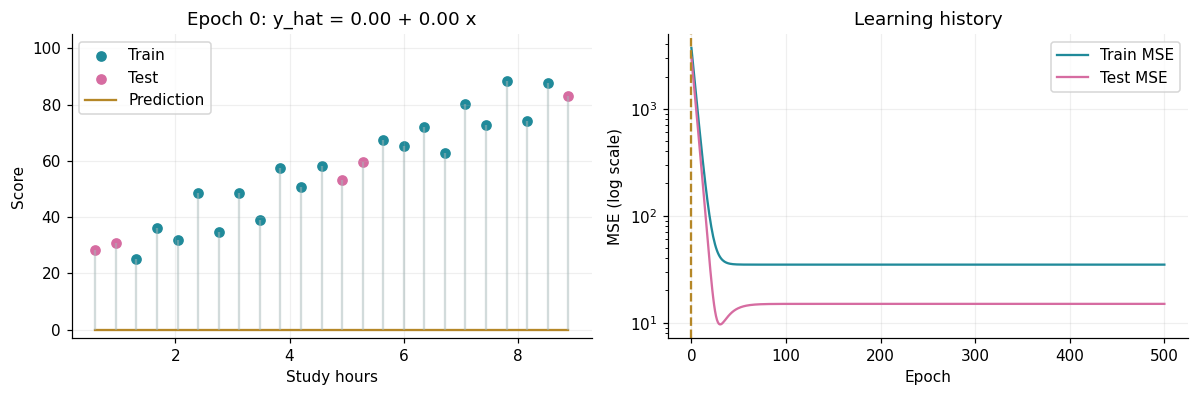

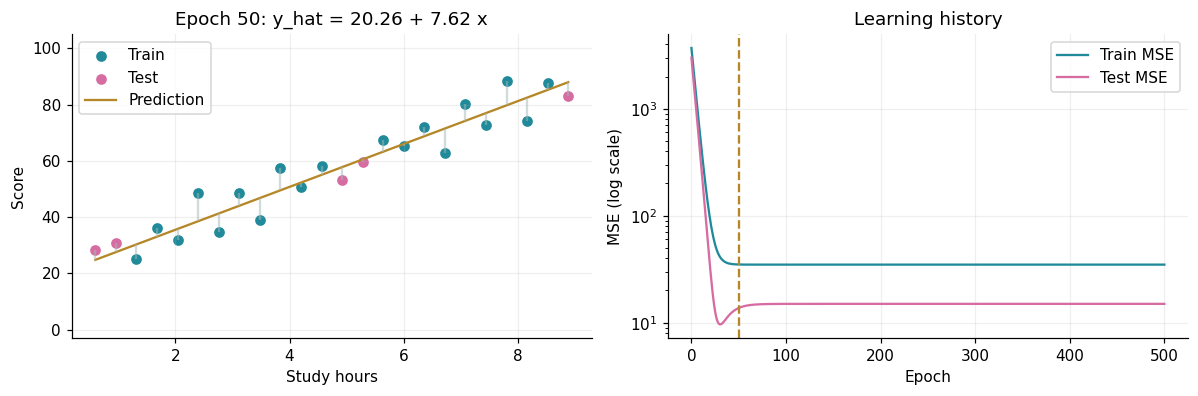

In [6]:
def plot_epoch(epoch=0):
    t = result['history'][epoch]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
    ax = axes[0]
    ax.scatter(X[train, 0], y[train], color='#208a9a', label='Train')
    ax.scatter(X[test, 0], y[test], color='#d66ca1', label='Test')
    xx = np.linspace(X.min(), X.max(), 100)
    coef = raw_coefficients(t, result['mu'], result['sd'])
    ax.plot(xx, coef[0] + coef[1] * xx, color='#b58727', label='Prediction')
    ax.vlines(X[:, 0], y, result['Z'] @ t, color='#a6b8b9', alpha=0.5)
    ax.set(xlabel='Study hours', ylabel='Score', ylim=(-3, 105),
           title=f'Epoch {epoch}: y_hat = {coef[0]:.2f} + {coef[1]:.2f} x')
    ax.legend()
    axes[1].semilogy(result['train_mse'], label='Train MSE', color='#208a9a')
    axes[1].semilogy(result['test_mse'], label='Test MSE', color='#d66ca1')
    axes[1].axvline(epoch, color='#b58727', linestyle='--')
    axes[1].set(xlabel='Epoch', ylabel='MSE (log scale)', title='Learning history')
    axes[1].legend()
    fig.tight_layout()
    plt.show()

plot_epoch(0)
plot_epoch(50)

In [7]:
# Tùy chọn: thanh kéo tương tác trong Jupyter / Colab.
try:
    from ipywidgets import interact, IntSlider
    interact(plot_epoch, epoch=IntSlider(min=0, max=len(result['history'])-1,
                                        value=0, continuous_update=False))
except ImportError:
    print('Chưa có ipywidgets. Chạy %pip install ipywidgets để bật thanh kéo.')
    print('Hoặc thay số trong plot_epoch(50) rồi chạy lại ô trên.')

Chưa có ipywidgets. Chạy %pip install ipywidgets để bật thanh kéo.
Hoặc thay số trong plot_epoch(50) rồi chạy lại ô trên.


### Bản đồ sai số: tại sao gọi là gradient descent?

Mỗi tọa độ (θ₀, θ₁) ứng với một đường dự đoán. Độ cao/màu biểu diễn MSE tập học. Thuật toán đi theo hướng ngược gradient để giảm MSE.

Với một biến đầu vào, hai tham số này mô tả đầy đủ bề mặt mất mát. Với nhiều biến, một bản đồ 2D chỉ là lát cắt hoặc hình chiếu, cần đọc chú thích cẩn thận.

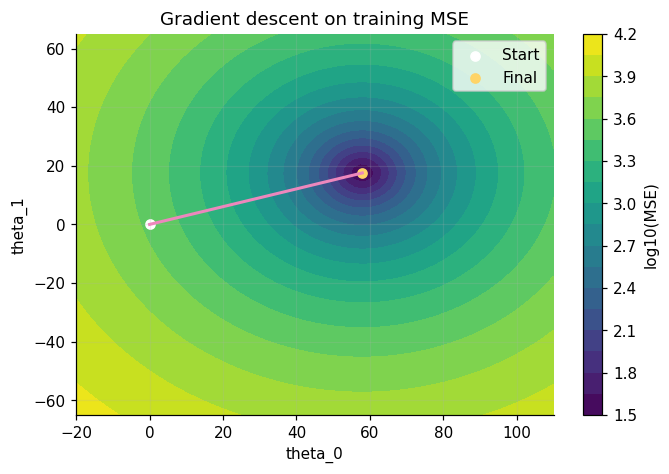

In [8]:
a = np.linspace(-20, 110, 80)
b = np.linspace(-65, 65, 80)
A, B = np.meshgrid(a, b)
zt = result['Z'][train, 1]
loss_grid = np.mean((A[..., None] + B[..., None] * zt - y[train])**2, axis=-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
contour = ax.contourf(A, B, np.log10(np.maximum(loss_grid, 1e-10)), levels=22, cmap='viridis')
h = result['history']
ax.plot(h[:, 0], h[:, 1], color='#ed87bd', linewidth=2)
ax.scatter(h[0, 0], h[0, 1], color='white', label='Start')
ax.scatter(h[-1, 0], h[-1, 1], color='#ffd467', label='Final')
ax.set(xlabel='theta_0', ylabel='theta_1', title='Gradient descent on training MSE')
fig.colorbar(contour, ax=ax, label='log10(MSE)')
ax.legend()
plt.show()

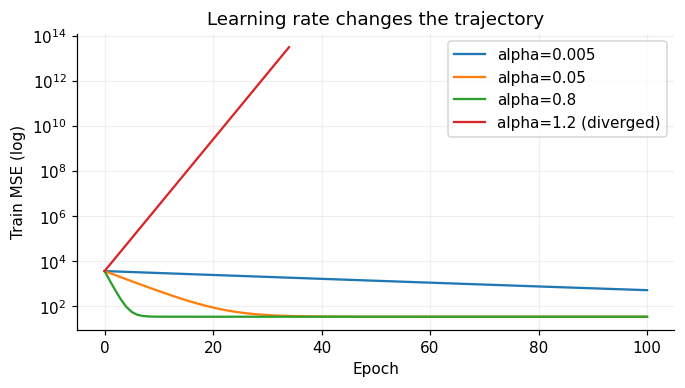

In [9]:
# Chỉ quan sát MSE tập học để hiểu tốc độ học; không chọn alpha theo tập test.
fig, ax = plt.subplots(figsize=(7, 3.5))
for lr in [0.005, 0.05, 0.8, 1.2]:
    trial = fit(X, y, alpha=lr, epochs=100)
    ax.semilogy(trial['train_mse'], label=f'alpha={lr}' + (' (diverged)' if trial['diverged'] else ''))
ax.set(xlabel='Epoch', ylabel='Train MSE (log)', title='Learning rate changes the trajectory')
ax.legend()
plt.show()

## 3. Nhiều biến: diện tích và số phòng

ŷ = b + w₁ × diện_tích + w₂ × số_phòng. Hai biến đầu vào tạo thành một mặt phẳng trong không gian 3D.

Diễn giải w₁: mức thay đổi dự đoán khi diện tích tăng một m², giữ số phòng cố định. Hai biến có đơn vị và thang đo khác nhau nên chuẩn hóa giúp quá trình học ổn định.

Dữ liệu giá nhà dưới đây là giả lập để quan sát; không dùng làm công cụ định giá thực tế.

[b, w_diện_tích, w_số_phòng] = [506.7518  23.9782 170.56  ]
MSE kiểm tra: 16550.52154012245
R² kiểm tra: 0.990872313020048


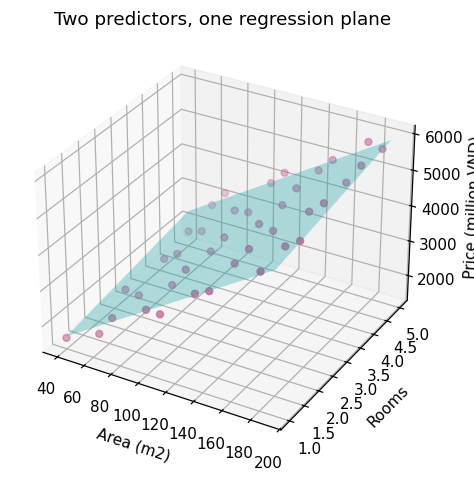

In [10]:
i = np.arange(40)
area = 40 + i * 37 % 150
rooms = 1 + i * 7 % 5
X_house = np.column_stack([area, rooms]).astype(float)
y_house = 450 + 24 * area + 180 * rooms + np.sin(i * 13) * 180
house = fit(X_house, y_house)
print('[b, w_diện_tích, w_số_phòng] =', raw_coefficients(house['theta'], house['mu'], house['sd']))
print('MSE kiểm tra:', house['test_mse'][-1])
print('R² kiểm tra:', r2(y_house[house['test']], house['Z'][house['test']] @ house['theta']))

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
u, v = np.meshgrid(np.linspace(40, 190, 16), np.linspace(1, 5, 10))
c = raw_coefficients(house['theta'], house['mu'], house['sd'])
ax.plot_surface(u, v, c[0]+c[1]*u+c[2]*v, alpha=0.35, color='#2eb6bc')
ax.scatter(area, rooms, y_house, color='#c36c9a', s=20)
ax.set(xlabel='Area (m2)', ylabel='Rooms', zlabel='Price (million VND)', title='Two predictors, one regression plane')
plt.show()

## 4. Dữ liệu thực: Iris

Nguồn: Fisher, R. (1936). Iris [Dataset]. UCI Machine Learning Repository. DOI: 10.24432/C56C76. CC BY 4.0.
https://archive.ics.uci.edu/dataset/53/iris

150 dòng từ tệp iris.data phiên bản legacy đã được nhúng bên dưới, không cần tải mạng. Dataset thường dùng cho phân loại loài hoa. Ở đây ta đặt một bài toán hồi quy khác: dự đoán chiều dài đài hoa (sepal_length, cm) từ chiều dài và chiều rộng cánh hoa (petal_length, petal_width, cm). Không đưa species hoặc cột mục tiêu vào X.

MSE có đơn vị cm². R² là thước đo so với dự đoán bằng trung bình y kiểm tra; R² có thể âm và không phải “phần trăm chính xác”.

In [11]:
IRIS_CSV = "sepal_length,sepal_width,petal_length,petal_width,species\n5.1,3.5,1.4,0.2,Iris-setosa\n4.9,3.0,1.4,0.2,Iris-setosa\n4.7,3.2,1.3,0.2,Iris-setosa\n4.6,3.1,1.5,0.2,Iris-setosa\n5.0,3.6,1.4,0.2,Iris-setosa\n5.4,3.9,1.7,0.4,Iris-setosa\n4.6,3.4,1.4,0.3,Iris-setosa\n5.0,3.4,1.5,0.2,Iris-setosa\n4.4,2.9,1.4,0.2,Iris-setosa\n4.9,3.1,1.5,0.1,Iris-setosa\n5.4,3.7,1.5,0.2,Iris-setosa\n4.8,3.4,1.6,0.2,Iris-setosa\n4.8,3.0,1.4,0.1,Iris-setosa\n4.3,3.0,1.1,0.1,Iris-setosa\n5.8,4.0,1.2,0.2,Iris-setosa\n5.7,4.4,1.5,0.4,Iris-setosa\n5.4,3.9,1.3,0.4,Iris-setosa\n5.1,3.5,1.4,0.3,Iris-setosa\n5.7,3.8,1.7,0.3,Iris-setosa\n5.1,3.8,1.5,0.3,Iris-setosa\n5.4,3.4,1.7,0.2,Iris-setosa\n5.1,3.7,1.5,0.4,Iris-setosa\n4.6,3.6,1.0,0.2,Iris-setosa\n5.1,3.3,1.7,0.5,Iris-setosa\n4.8,3.4,1.9,0.2,Iris-setosa\n5.0,3.0,1.6,0.2,Iris-setosa\n5.0,3.4,1.6,0.4,Iris-setosa\n5.2,3.5,1.5,0.2,Iris-setosa\n5.2,3.4,1.4,0.2,Iris-setosa\n4.7,3.2,1.6,0.2,Iris-setosa\n4.8,3.1,1.6,0.2,Iris-setosa\n5.4,3.4,1.5,0.4,Iris-setosa\n5.2,4.1,1.5,0.1,Iris-setosa\n5.5,4.2,1.4,0.2,Iris-setosa\n4.9,3.1,1.5,0.1,Iris-setosa\n5.0,3.2,1.2,0.2,Iris-setosa\n5.5,3.5,1.3,0.2,Iris-setosa\n4.9,3.1,1.5,0.1,Iris-setosa\n4.4,3.0,1.3,0.2,Iris-setosa\n5.1,3.4,1.5,0.2,Iris-setosa\n5.0,3.5,1.3,0.3,Iris-setosa\n4.5,2.3,1.3,0.3,Iris-setosa\n4.4,3.2,1.3,0.2,Iris-setosa\n5.0,3.5,1.6,0.6,Iris-setosa\n5.1,3.8,1.9,0.4,Iris-setosa\n4.8,3.0,1.4,0.3,Iris-setosa\n5.1,3.8,1.6,0.2,Iris-setosa\n4.6,3.2,1.4,0.2,Iris-setosa\n5.3,3.7,1.5,0.2,Iris-setosa\n5.0,3.3,1.4,0.2,Iris-setosa\n7.0,3.2,4.7,1.4,Iris-versicolor\n6.4,3.2,4.5,1.5,Iris-versicolor\n6.9,3.1,4.9,1.5,Iris-versicolor\n5.5,2.3,4.0,1.3,Iris-versicolor\n6.5,2.8,4.6,1.5,Iris-versicolor\n5.7,2.8,4.5,1.3,Iris-versicolor\n6.3,3.3,4.7,1.6,Iris-versicolor\n4.9,2.4,3.3,1.0,Iris-versicolor\n6.6,2.9,4.6,1.3,Iris-versicolor\n5.2,2.7,3.9,1.4,Iris-versicolor\n5.0,2.0,3.5,1.0,Iris-versicolor\n5.9,3.0,4.2,1.5,Iris-versicolor\n6.0,2.2,4.0,1.0,Iris-versicolor\n6.1,2.9,4.7,1.4,Iris-versicolor\n5.6,2.9,3.6,1.3,Iris-versicolor\n6.7,3.1,4.4,1.4,Iris-versicolor\n5.6,3.0,4.5,1.5,Iris-versicolor\n5.8,2.7,4.1,1.0,Iris-versicolor\n6.2,2.2,4.5,1.5,Iris-versicolor\n5.6,2.5,3.9,1.1,Iris-versicolor\n5.9,3.2,4.8,1.8,Iris-versicolor\n6.1,2.8,4.0,1.3,Iris-versicolor\n6.3,2.5,4.9,1.5,Iris-versicolor\n6.1,2.8,4.7,1.2,Iris-versicolor\n6.4,2.9,4.3,1.3,Iris-versicolor\n6.6,3.0,4.4,1.4,Iris-versicolor\n6.8,2.8,4.8,1.4,Iris-versicolor\n6.7,3.0,5.0,1.7,Iris-versicolor\n6.0,2.9,4.5,1.5,Iris-versicolor\n5.7,2.6,3.5,1.0,Iris-versicolor\n5.5,2.4,3.8,1.1,Iris-versicolor\n5.5,2.4,3.7,1.0,Iris-versicolor\n5.8,2.7,3.9,1.2,Iris-versicolor\n6.0,2.7,5.1,1.6,Iris-versicolor\n5.4,3.0,4.5,1.5,Iris-versicolor\n6.0,3.4,4.5,1.6,Iris-versicolor\n6.7,3.1,4.7,1.5,Iris-versicolor\n6.3,2.3,4.4,1.3,Iris-versicolor\n5.6,3.0,4.1,1.3,Iris-versicolor\n5.5,2.5,4.0,1.3,Iris-versicolor\n5.5,2.6,4.4,1.2,Iris-versicolor\n6.1,3.0,4.6,1.4,Iris-versicolor\n5.8,2.6,4.0,1.2,Iris-versicolor\n5.0,2.3,3.3,1.0,Iris-versicolor\n5.6,2.7,4.2,1.3,Iris-versicolor\n5.7,3.0,4.2,1.2,Iris-versicolor\n5.7,2.9,4.2,1.3,Iris-versicolor\n6.2,2.9,4.3,1.3,Iris-versicolor\n5.1,2.5,3.0,1.1,Iris-versicolor\n5.7,2.8,4.1,1.3,Iris-versicolor\n6.3,3.3,6.0,2.5,Iris-virginica\n5.8,2.7,5.1,1.9,Iris-virginica\n7.1,3.0,5.9,2.1,Iris-virginica\n6.3,2.9,5.6,1.8,Iris-virginica\n6.5,3.0,5.8,2.2,Iris-virginica\n7.6,3.0,6.6,2.1,Iris-virginica\n4.9,2.5,4.5,1.7,Iris-virginica\n7.3,2.9,6.3,1.8,Iris-virginica\n6.7,2.5,5.8,1.8,Iris-virginica\n7.2,3.6,6.1,2.5,Iris-virginica\n6.5,3.2,5.1,2.0,Iris-virginica\n6.4,2.7,5.3,1.9,Iris-virginica\n6.8,3.0,5.5,2.1,Iris-virginica\n5.7,2.5,5.0,2.0,Iris-virginica\n5.8,2.8,5.1,2.4,Iris-virginica\n6.4,3.2,5.3,2.3,Iris-virginica\n6.5,3.0,5.5,1.8,Iris-virginica\n7.7,3.8,6.7,2.2,Iris-virginica\n7.7,2.6,6.9,2.3,Iris-virginica\n6.0,2.2,5.0,1.5,Iris-virginica\n6.9,3.2,5.7,2.3,Iris-virginica\n5.6,2.8,4.9,2.0,Iris-virginica\n7.7,2.8,6.7,2.0,Iris-virginica\n6.3,2.7,4.9,1.8,Iris-virginica\n6.7,3.3,5.7,2.1,Iris-virginica\n7.2,3.2,6.0,1.8,Iris-virginica\n6.2,2.8,4.8,1.8,Iris-virginica\n6.1,3.0,4.9,1.8,Iris-virginica\n6.4,2.8,5.6,2.1,Iris-virginica\n7.2,3.0,5.8,1.6,Iris-virginica\n7.4,2.8,6.1,1.9,Iris-virginica\n7.9,3.8,6.4,2.0,Iris-virginica\n6.4,2.8,5.6,2.2,Iris-virginica\n6.3,2.8,5.1,1.5,Iris-virginica\n6.1,2.6,5.6,1.4,Iris-virginica\n7.7,3.0,6.1,2.3,Iris-virginica\n6.3,3.4,5.6,2.4,Iris-virginica\n6.4,3.1,5.5,1.8,Iris-virginica\n6.0,3.0,4.8,1.8,Iris-virginica\n6.9,3.1,5.4,2.1,Iris-virginica\n6.7,3.1,5.6,2.4,Iris-virginica\n6.9,3.1,5.1,2.3,Iris-virginica\n5.8,2.7,5.1,1.9,Iris-virginica\n6.8,3.2,5.9,2.3,Iris-virginica\n6.7,3.3,5.7,2.5,Iris-virginica\n6.7,3.0,5.2,2.3,Iris-virginica\n6.3,2.5,5.0,1.9,Iris-virginica\n6.5,3.0,5.2,2.0,Iris-virginica\n6.2,3.4,5.4,2.3,Iris-virginica\n5.9,3.0,5.1,1.8,Iris-virginica\n"
records = list(csv.DictReader(io.StringIO(IRIS_CSV)))
X_iris = np.array([[float(r['petal_length']), float(r['petal_width'])] for r in records])
y_iris = np.array([float(r['sepal_length']) for r in records])
iris = fit(X_iris, y_iris)
print('Số mẫu:', len(records), '| Train / test:', len(iris['train']), len(iris['test']))
print('[b, w1, w2]:', raw_coefficients(iris['theta'], iris['mu'], iris['sd']))
print('MSE kiểm tra (cm²):', round(iris['test_mse'][-1], 6))
print('R² kiểm tra:', round(r2(y_iris[iris['test']], iris['Z'][iris['test']] @ iris['theta']), 6))

Số mẫu: 150 | Train / test: 120 30
[b, w1, w2]: [ 4.1888  0.517  -0.248 ]
MSE kiểm tra (cm²): 0.144229
R² kiểm tra: 0.774426


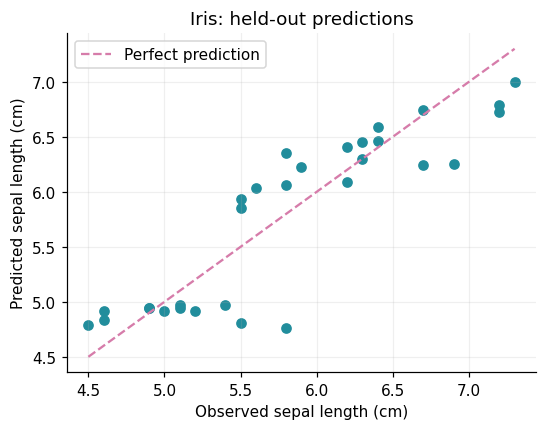

In [12]:
pred_iris = iris['Z'][iris['test']] @ iris['theta']
truth = y_iris[iris['test']]
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(truth, pred_iris, color='#218d9c')
lo, hi = min(truth.min(), pred_iris.min()), max(truth.max(), pred_iris.max())
ax.plot([lo, hi], [lo, hi], '--', color='#d67caa', label='Perfect prediction')
ax.set(xlabel='Observed sepal length (cm)', ylabel='Predicted sepal length (cm)', title='Iris: held-out predictions')
ax.legend()
plt.show()

### Dùng CSV của em

Tải CSV về từ nút “CSV” trên web để dùng đúng các giá trị đã quan sát. Với cùng thứ tự dòng, seed và tỷ lệ chia, notebook sẽ tạo cùng tập học/kiểm tra.

Sửa csv_path, feature_names và target_name trong ô dưới. Dùng cột số, mục tiêu liên tục, loại cột ID và cột có sẵn đáp án. Hàm báo số dòng thiếu/không phải số bị loại bỏ.

Không kết luận mô hình tốt chỉ vì MSE tập học nhỏ. Nếu thử nhiều cấu hình, dùng validation/cross-validation; giữ tập test cuối cùng chưa sử dụng.

In [13]:
def load_csv_data(path, feature_names, target_name, delimiter=','):
    if not 1 <= len(feature_names) <= 3 or target_name in feature_names:
        raise ValueError('Chọn 1-3 biến đầu vào, không chứa cột mục tiêu.')
    rows, skipped = [], 0
    with open(path, encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f, delimiter=delimiter)
        needed = feature_names + [target_name]
        if not all(k in (reader.fieldnames or []) for k in needed):
            raise ValueError('Thiếu cột cần thiết trong CSV.')
        for row in reader:
            try:
                values = [float(row[k]) for k in needed]
                if not np.isfinite(values).all():
                    raise ValueError('non-finite')
                rows.append(values)
            except (ValueError, TypeError):
                skipped += 1
    if len(rows) < 6:
        raise ValueError('Cần ít nhất 6 dòng hợp lệ.')
    data = np.array(rows)
    print('Dòng dùng:', len(rows), '| Dòng loại:', skipped)
    return data[:, :-1], data[:, -1]

csv_path = None  # Ví dụ: 'du_lieu_hoi_quy.csv'
feature_names = ['gio_hoc']
target_name = 'diem'
if csv_path is not None:
    X_custom, y_custom = load_csv_data(csv_path, feature_names, target_name)
    custom = fit(X_custom, y_custom)
    print('Hệ số gốc:', raw_coefficients(custom['theta'], custom['mu'], custom['sd']))
    print('Test MSE:', custom['test_mse'][-1])
else:
    print('Đặt csv_path thành tên tệp của em rồi chạy lại ô này.')

Đặt csv_path thành tên tệp của em rồi chạy lại ô này.


## 5. Dự đoán mới và kiểm chứng

Dự đoán mới phải dùng μ và σ đã học, không tính lại trên mẫu mới. Nếu đầu vào nằm ngoài phạm vi tập học thì đó là ngoại suy.

np.linalg.lstsq cung cấp nghiệm bình phương tối thiểu để đối chiếu. Với các biến tương quan mạnh hoặc ngân sách vòng lặp ít, gradient descent có thể chưa tới nghiệm đó.

In [14]:
def predict_new(model, X_new):
    X_new = np.asarray(X_new, dtype=float)
    Z_new = np.column_stack([np.ones(len(X_new)), (X_new-model['mu'])/model['sd']])
    return Z_new @ model['theta']

print('Điểm dự đoán cho 3 và 6 giờ:', predict_new(result, [[3], [6]]))
least_squares, *_ = np.linalg.lstsq(result['Z'][train], y[train], rcond=None)
print('θ gradient descent:', result['theta'])
print('θ least squares:', least_squares)
print('Khoảng cách hai nghiệm:', np.linalg.norm(result['theta'] - least_squares))

# Kiểm tra gradient bằng sai phân số trên cùng tập học.
t = np.array([0.3, 0.4])
g = 2 / len(train) * result['Z'][train].T @ (result['Z'][train] @ t - y[train])
eps = 1e-5
numerical = []
for j in range(len(t)):
    shift = np.eye(len(t))[j] * eps
    numerical.append((mse(y[train], result['Z'][train] @ (t+shift))-
                      mse(y[train], result['Z'][train] @ (t-shift))) / (2*eps))
assert np.allclose(g, numerical, atol=1e-6)
print('Gradient kiểm tra: OK')

Điểm dự đoán cho 3 và 6 giờ: [43.3491 66.3364]
θ gradient descent: [57.9158 17.5485]
θ least squares: [57.9158 17.5485]
Khoảng cách hai nghiệm: 5.0867118742119833e-14
Gradient kiểm tra: OK


### Tự kiểm tra hiểu biết

1. Giữ w cố định và tăng b: đường dự đoán chuyển thế nào?
2. Vì sao không lấy trung bình sai số có dấu làm hàm mất mát?
3. Nếu gradient của một hệ số âm, cập nhật sẽ tăng hay giảm hệ số đó?
4. Tại sao giá nhà dễ phân kỳ khi bỏ chuẩn hóa và giữ alpha = 0.05?
5. Giữ diện tích cố định, hệ số số phòng mô tả điều gì?
6. Vì sao không được tính μ, σ trên cả tập học và tập kiểm tra?

**Gợi ý đáp án:** (1) Tịnh tiến lên. (2) Sai số âm và dương triệt tiêu nhau. (3) Tăng vì trừ số âm. (4) Đặc trưng diện tích có thang đo lớn, bước cập nhật có thể quá lớn. (5) Mức thay đổi giá dự đoán khi thêm một phòng, các biến khác cố định. (6) Làm lộ thông tin từ tập kiểm tra vào quy trình học.

Thử sửa một điểm thành ngoại lệ, chạy lại toàn bộ notebook và so sánh đường thẳng. Sau đó giải thích bằng công thức e² vì sao ngoại lệ ảnh hưởng mạnh.

Nguồn thư viện: https://numpy.org/doc/ ; https://matplotlib.org/stable/ ; https://ipywidgets.readthedocs.io/ .